# 05 — Build master dataset & candidate feature pool (Bogotá)

Merges the cleaned station-network daily series, ERA5 daily aggregates, and fire hotspot
counts into one table, then builds a **wide candidate feature pool** analogous to Bety's
Table A1 — station meteorology, other co-located pollutants, ERA5 fields (including
radiation), fire hotspots, and calendar effects, each same-day and lagged 1-3 days — so
notebook 06's sequential feature selection has a real search space to work with instead
of a couple of hand-picked predictors.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("/path/to/project")
sys.path.insert(0, str(PROJECT_ROOT / "Scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common.external_data import FIRE_SOURCE_REGIONS, bearing_from_bogota

DATA_DIR = PROJECT_ROOT / "Data" / "processed" / "colombia" / "bogota"
FIG_DIR = PROJECT_ROOT / "Scripts" / "colombia" / "bogota" / "figures"

network = pd.read_parquet(DATA_DIR / "bogota_network_daily_clean.parquet")
era5 = pd.read_parquet(DATA_DIR / "bogota_era5_daily.parquet")
hotspots = pd.read_parquet(DATA_DIR / "bogota_hotspots_daily.parquet")
lts = pd.read_parquet(DATA_DIR / "bogota_lts_daily.parquet")
no = pd.read_parquet(DATA_DIR / "bogota_no_daily.parquet")  # NO -- vehicle/combustion proxy, see markdown
co = pd.read_parquet(DATA_DIR / "bogota_co_daily.parquet")  # CO -- combustion proxy, O3-precursor via HO2 cycle
so2 = pd.read_parquet(DATA_DIR / "bogota_so2_daily.parquet")  # SO2 -- combustion/industrial proxy, sulfate precursor

# w700 (v6, vertical velocity at 700hPa) may not be downloaded yet -- tolerate its
# absence so this notebook can be re-run now with everything else already fixed
# (v7 hotspot regions) and re-run again automatically once v6 finishes.
w700_path = DATA_DIR / "bogota_w700_daily.parquet"
w700 = pd.read_parquet(w700_path) if w700_path.exists() else None

print("network:", network.shape, network['date'].min(), network['date'].max())
print("era5:", era5.shape, era5['date'].min(), era5['date'].max())
print("hotspots:", hotspots.shape, hotspots['date'].min(), hotspots['date'].max())
print("lts:", lts.shape, lts['date'].min(), lts['date'].max())
print("no:", no.shape, no['date'].min(), no['date'].max(), "non-null:", no['no'].notna().sum())
print("co:", co.shape, "non-null:", co['co'].notna().sum())
print("so2:", so2.shape, "non-null:", so2['so2'].notna().sum())
if w700 is not None:
    print("w700:", w700.shape, w700['date'].min(), w700['date'].max())
else:
    print("w700: not yet available, skipping (v6 ERA5 batch still downloading)")


network: (4383, 12) 2014-01-01 00:00:00 2025-12-31 00:00:00
era5: (4384, 12) 2013-12-31 00:00:00 2025-12-31 00:00:00
hotspots: (4017, 12) 2013-01-01 00:00:00 2023-12-31 00:00:00
lts: (4384, 3) 2013-12-31 00:00:00 2025-12-31 00:00:00
no: (3652, 2) 2013-01-01 00:00:00 2022-12-31 00:00:00 non-null: 3650
co: (3652, 2) non-null: 3650
so2: (2557, 2) non-null: 1723
w700: (4384, 2) 2013-12-31 00:00:00 2025-12-31 00:00:00


## Merge

In [2]:
df = (network.merge(era5, on='date', how='left')
             .merge(hotspots, on='date', how='left')
             .merge(lts, on='date', how='left')
             .merge(no, on='date', how='left')
             .merge(co, on='date', how='left')
             .merge(so2, on='date', how='left'))
if w700 is not None:
    df = df.merge(w700, on='date', how='left')
df = df.sort_values('date').reset_index(drop=True)
print(df.shape)
df.isna().mean().sort_values(ascending=False)


(4383, 40)


rh_10m                       0.750171
temp_10m                     0.749943
so2                          0.606890
co                           0.250513
no                           0.250513
hotspots_nevados             0.166781
hotspots_magdalena_valley    0.166781
hotspots_caqueta             0.166781
hotspots_sector_E            0.166781
hotspots_sector_SE           0.166781
hotspots_sector_S            0.166781
hotspots_sector_SW           0.166781
hotspots_sector_W            0.166781
hotspots_sector_NW           0.166781
hotspots_sector_N            0.166781
hotspots_sector_NE           0.166781
pressure                     0.166781
o3                           0.090121
no2                          0.085330
rh_2m                        0.083504
temp_2m                      0.083276
wind_dir                     0.083276
wind_speed                   0.083276
pm10                         0.000228
lts_morning                  0.000000
lts                          0.000000
date        

## Engineered features

- Wind direction as sin/cos (a bare degree value is not meaningful to a model/equation).
- Calendar effects as sin/cos of day-of-year and month, plus a weekend flag — the
  Casallas paper found both a weekly (weekday traffic) and seasonal (wildfire-season)
  signal for Bogotá.
- Ventilation coefficient (BLH x **station** wind speed) included *in* the candidate
  pool, not imposed as the only wind/BLH-related feature. Wind comes from the SISAIRE
  gauges, not ERA5 -- the station network already measures it directly and is the
  better source; ERA5 here only supplies BLH, radiation and precipitation, none of
  which any local gauge provides.
- **Wind-transport-conditioned hotspots** (new): raw hotspot counts per source region
  (from notebook 04) reflect fire *activity*, not whether that smoke was actually
  blowing toward Bogotá that day. For each region we compute the compass bearing from
  Bogotá to the region's center, then a same-day transport-alignment factor
  `max(0, cos(wind_dir - bearing))` -- 1 when the day's wind blows straight from that
  region toward the city, 0 or negative (clipped to 0) when it's blowing the other way.
  `hotspots_<region>_transport = hotspots_<region> * alignment` operationalizes the
  actual causal chain (source activity AND favorable transport), rather than source
  activity alone, addressing the gap flagged after notebook 04.
- **Emissions trapped by stagnation** (new): `no2 / (1 + ventilation_station)` -- NO2 is
  a primary-emission proxy (traffic/combustion), and dividing by ventilation capacity
  represents the causal idea that the *same* emission rate produces more surface
  accumulation when dispersion is poor. This is a genuine interaction hypothesis, not
  just NO2 and ventilation offered separately and hoping a linear model finds it.
- **v4 additions** (user request — the discovered equation leaned on a raw day-of-year
  term, which doesn't explain the underlying physical mechanism; asked for more direct
  stagnation/stability physics and variable products instead of accepting "season"):
  - **Timezone fix**: ERA5 timestamps are UTC; Bogotá is fixed UTC-5 (no DST). All ERA5
    daily aggregation (in `external_data.py`) now shifts to local time *before*
    resampling to daily buckets -- a naive UTC-day resample was misaligned with the
    SISAIRE stations' local-day PM2.5 by up to 5 hours, which would corrupt anything
    computed over a specific time-of-day window (like the two features below).
  - `lts` / `lts_morning` (Lower Tropospheric Stability, from notebook 03's new ERA5
    pressure-level pull): `theta_700 - theta_surface`, computed both as a full-day mean
    and specifically over the local 05:00-08:00 window (the actual overnight/pre-dawn
    inversion state, which a 24h mean dilutes with the well-mixed daytime boundary
    layer). A strong inversion (high LTS) traps pollution near the surface — the real
    physical mechanism a seasonal proxy can only gesture at. Analogous to the Estimated
    Inversion Strength diagnostic the group's own papers cite as important.
  - `blh_morning_mean`: mean BLH over the same local 05:00-08:00 window, for the same
    reason -- Bogotá's documented AM PM2.5 peak (Tendencies_PM2p5.pdf) occurs at 8-9h
    local, right as this window ends, so this is closer to Bety's approach of using
    the state right before/at the extreme rather than a diluted full-day statistic.
  - `ventilation_min = blh_min * wind_speed`: worst-case-of-the-day dispersion (using
    the daily *minimum* BLH rather than the mean), since stagnation episodes are about
    the worst hours, not the daily average.
  - `fog_stagnation = rh_2m / (1 + wind_speed)`: calm + humid conditions favor
    hygroscopic growth of particles (aerosol water uptake directly increases measured
    PM2.5 mass) and fog/haze formation — answers the "w?? and rh" product request.
  - `dry_stagnation = 1 / ((1 + wind_speed) * (1 + precip_total_mm))`: calm + dry
    conditions (no washout, no dispersion) — the classic wildfire-season meteorological
    stagnation signature, as a variable in its own right rather than inferred from month.
  - `secondary_pm_proxy = no2 * radiation_mean`: NOx + strong sunlight drives
    photochemical secondary aerosol formation (analogous to how NOx + sunlight drives
    O3), a real chemical mechanism rather than NO2 and radiation offered separately.
- **v6 additions** (user request after seeing R²=0.493/0.41 for the physical model —
  wanted R²>=0.7 while staying physical, i.e. no `pm25_lag1`): four new independent
  physical axes, all requiring ERA5 since no local gauge provides them:
  - `tcwv`: total column water vapour -- integrated atmospheric moisture, distinct from
    surface RH.
  - `sensible_heat_flux`: the thermal driver of daytime convective boundary-layer
    growth/mixing (distinct from mechanical/wind-driven mixing).
  - `tke_proxy`: a turbulent-kinetic-energy-like proxy (half the within-day variance of
    ERA5's 10m u/v wind components) -- needs ERA5's hourly resolution specifically,
    since station wind is daily-mean only and can't reveal sub-daily variability.
  - `w700`: ERA5 vertical velocity (omega) at 700 hPa -- synoptic-scale subsidence
    (positive, stable/capping/pollution-trapping) vs. ascent/instability (negative), a
    different physical axis from LTS's temperature-based inversion strength.
- Lag features (1-3 days) for every meteorological/pollutant/hotspot predictor, plus a
  1-day lag of PM2.5 itself as an autoregressive baseline candidate (flagged separately
  since an autoregressive term tends to dominate feature selection and can mask the
  physical drivers we actually care about — notebook 06 reports results with and without
  it available).


In [3]:
df['wind_dir_sin'] = np.sin(np.deg2rad(df['wind_dir']))
df['wind_dir_cos'] = np.cos(np.deg2rad(df['wind_dir']))

doy = df['date'].dt.dayofyear
df['doy_sin'] = np.sin(2 * np.pi * doy / 365.25)
df['doy_cos'] = np.cos(2 * np.pi * doy / 365.25)
month = df['date'].dt.month
df['month_sin'] = np.sin(2 * np.pi * month / 12)
df['month_cos'] = np.cos(2 * np.pi * month / 12)
df['day_of_week'] = df['date'].dt.dayofweek
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)

df['ventilation_station'] = df['blh_mean'] * df['wind_speed']

# Wind-transport-conditioned hotspots: alignment=1 when today's wind blows straight
# from the region toward Bogotá (wind_dir, meteorological "from" convention, matches
# the bearing from Bogotá to the region), 0 when blowing the other way (clipped, since
# a fire directly downwind of the city contributes nothing to the city's exposure).
# Two kinds of hotspot columns now (see notebook 04's v7 revision): named point
# sources (bearing looked up from FIRE_SOURCE_REGIONS) and compass-direction sectors
# (bearing is just the sector's own center, e.g. NE=45 deg -- no lookup needed).
SECTOR_BEARINGS = {name: i * 45.0 for i, name in enumerate(["N", "NE", "E", "SE", "S", "SW", "W", "NW"])}

point_region_cols = [c for c in df.columns if c.startswith('hotspots_') and not c.startswith('hotspots_sector_')]
sector_cols = [c for c in df.columns if c.startswith('hotspots_sector_')]

for region_col in point_region_cols:
    region_name = region_col.replace('hotspots_', '')
    bearing = bearing_from_bogota(FIRE_SOURCE_REGIONS[region_name]['lat'], FIRE_SOURCE_REGIONS[region_name]['lon'])
    alignment = np.cos(np.deg2rad(df['wind_dir'] - bearing)).clip(lower=0)
    df[f'{region_col}_transport'] = df[region_col] * alignment

for sector_col in sector_cols:
    sector_name = sector_col.replace('hotspots_sector_', '')
    bearing = SECTOR_BEARINGS[sector_name]
    alignment = np.cos(np.deg2rad(df['wind_dir'] - bearing)).clip(lower=0)
    df[f'{sector_col}_transport'] = df[sector_col] * alignment

# Emissions trapped by stagnation: same NO2 emission rate, worse accumulation when
# dispersion (ventilation) is poor -- a genuine interaction hypothesis, not just NO2
# and ventilation offered separately.
df['no2_stagnation'] = df['no2'] / (1 + df['ventilation_station'])

# v4: stagnation/stability physics and variable products (see markdown above).
df['ventilation_min'] = df['blh_min'] * df['wind_speed']
df['fog_stagnation'] = df['rh_2m'] / (1 + df['wind_speed'])
df['dry_stagnation'] = 1 / ((1 + df['wind_speed']) * (1 + df['precip_total_mm']))
df['secondary_pm_proxy'] = df['no2'] * df['radiation_mean']

# NO and NOx (=NO+NO2) as vehicle-emissions proxies (user request) -- NO is the more
# direct combustion tracer (NO2 also forms secondarily from NO+O3 downwind), and NOx is
# the combined primary-emission total, following the same logic as keeping NO2 itself:
# not causally downstream of PM2.5, so no leakage risk the way PM10/O3 were.
df['nox'] = df['no'] + df['no2']


In [4]:
LAG_DAYS = [1, 2, 3]
hotspot_region_cols = [c for c in df.columns if c.startswith('hotspots_')]  # raw + _transport variants
print(f"{len(hotspot_region_cols)} fire source-region columns (raw + transport-weighted):", hotspot_region_cols)

LAG_VARS = [
    'pm10', 'no2', 'o3', 'wind_speed', 'temp_2m', 'rh_2m', 'pressure',
    'blh_mean', 'blh_morning_mean', 'radiation_mean', 'precip_total_mm',
    'ventilation_station', 'no2_stagnation',
    'lts', 'lts_morning', 'ventilation_min', 'fog_stagnation', 'dry_stagnation', 'secondary_pm_proxy',
    'tcwv', 'sensible_heat_flux', 'tke_proxy', 'w700', 'no', 'nox', 'co', 'so2',
] + hotspot_region_cols
df = df.set_index('date')
for var in LAG_VARS:
    if var not in df.columns:
        continue
    for lag in LAG_DAYS:
        df[f'{var}_lag{lag}'] = df[var].shift(lag)

# PM2.5 autoregressive candidate, tracked separately (see markdown above).
df['pm25_lag1'] = df['pm25'].shift(1)
df = df.reset_index()

candidate_cols = [c for c in df.columns if c not in ('date', 'pm25')]
print(f"{len(candidate_cols)} candidate predictor columns")


22 fire source-region columns (raw + transport-weighted): ['hotspots_caqueta', 'hotspots_magdalena_valley', 'hotspots_nevados', 'hotspots_sector_N', 'hotspots_sector_NE', 'hotspots_sector_E', 'hotspots_sector_SE', 'hotspots_sector_S', 'hotspots_sector_SW', 'hotspots_sector_W', 'hotspots_sector_NW', 'hotspots_caqueta_transport', 'hotspots_magdalena_valley_transport', 'hotspots_nevados_transport', 'hotspots_sector_N_transport', 'hotspots_sector_NE_transport', 'hotspots_sector_E_transport', 'hotspots_sector_SE_transport', 'hotspots_sector_S_transport', 'hotspots_sector_SW_transport', 'hotspots_sector_W_transport', 'hotspots_sector_NW_transport']
212 candidate predictor columns


/var/folders/30/gtfddbxx5z3f_hc8v4br4pkh0000gn/T/ipykernel_49317/2207226677.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'{var}_lag{lag}'] = df[var].shift(lag)
/var/folders/30/gtfddbxx5z3f_hc8v4br4pkh0000gn/T/ipykernel_49317/2207226677.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'{var}_lag{lag}'] = df[var].shift(lag)
/var/folders/30/gtfddbxx5z3f_hc8v4br4pkh0000gn/T/ipykernel_49317/2207226677.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` m

## Verification: ventilation coefficient should anti-correlate with PM2.5

Sanity check from the project plan — higher ventilation (BLH x wind speed, i.e. better
dilution) should coincide with lower PM2.5, matching both established theory and the
paper's own findings for Bogotá.


In [5]:
for col in ['ventilation_station', 'blh_mean', 'wind_speed']:
    if col in df.columns:
        corr = df[['pm25', col]].dropna().corr().iloc[0, 1]
        print(f"corr(pm25, {col}) = {corr:.3f}")


corr(pm25, ventilation_station) = -0.290
corr(pm25, blh_mean) = -0.247
corr(pm25, wind_speed) = -0.295


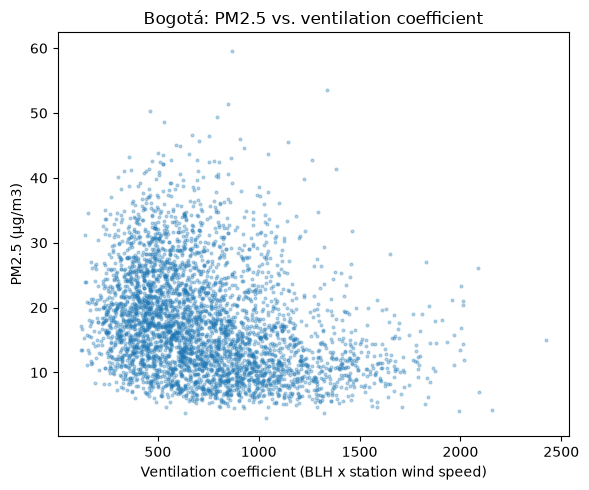

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
sub = df.dropna(subset=['pm25', 'ventilation_station'])
ax.scatter(sub['ventilation_station'], sub['pm25'], s=4, alpha=0.3)
ax.set_xlabel('Ventilation coefficient (BLH x station wind speed)')
ax.set_ylabel('PM2.5 (µg/m3)')
ax.set_title('Bogotá: PM2.5 vs. ventilation coefficient')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pm25_vs_ventilation.png', dpi=150)
plt.show()


## Verification: new v4 stagnation/stability features

`lts` should *positively* correlate with PM2.5 (stronger inversion -> more trapping);
`ventilation_min`, `dry_stagnation` and `fog_stagnation` should behave like `ventilation_station`
in sign (dispersion-related). `secondary_pm_proxy` should be positive (more NO2 + more sun ->
more secondary aerosol).


In [7]:
for col in ['lts', 'lts_morning', 'blh_morning_mean', 'ventilation_min', 'fog_stagnation', 'dry_stagnation', 'secondary_pm_proxy',
            'tcwv', 'sensible_heat_flux', 'tke_proxy', 'w700']:
    if col not in df.columns:
        print(f"{col}: not yet available, skipping")
        continue
    corr = df[['pm25', col]].dropna().corr().iloc[0, 1]
    print(f"corr(pm25, {col}) = {corr:.3f}")


corr(pm25, lts) = 0.347
corr(pm25, lts_morning) = 0.256
corr(pm25, blh_morning_mean) = -0.398
corr(pm25, ventilation_min) = -0.387
corr(pm25, fog_stagnation) = 0.254
corr(pm25, dry_stagnation) = -0.383
corr(pm25, secondary_pm_proxy) = 0.413
corr(pm25, tcwv) = -0.101
corr(pm25, sensible_heat_flux) = -0.190
corr(pm25, tke_proxy) = 0.179
corr(pm25, w700) = -0.594


## Verification: NO / NOx (vehicle-emissions proxies)

Both should correlate positively with PM2.5 if they're tracking the same traffic/
combustion emissions that produce PM2.5 (same logic as NO2's own positive raw
correlation, r=0.360, found earlier) -- reported, not assumed, since NO's atmospheric
role (titration, short lifetime near roads) differs enough from NO2 that the sign isn't
guaranteed to be as clean.

In [8]:
for col in ['no', 'nox', 'co', 'so2']:
    if col in df.columns:
        corr = df[['pm25', col]].dropna().corr().iloc[0, 1]
        n = df[['pm25', col]].dropna().shape[0]
        print(f"corr(pm25, {col}) = {corr:.3f}  (n={n})")

corr(pm25, no) = 0.265  (n=3285)
corr(pm25, nox) = 0.393  (n=2920)
corr(pm25, co) = 0.618  (n=3285)
corr(pm25, so2) = -0.013  (n=1723)


## Verification: does each fire source region correlate with PM2.5 in its expected season?

Per Casallas et al. 2024, Bogotá's PM2.5 plume sources are season-dependent (Caquetá in
DJF; CVB/north Colombia in MAM; eastern plains/Magdalena Valley/Nevados in JJA-SON). This
checks same-day correlation of each region's hotspot count with PM2.5, split by season,
as a rough consistency check -- not expected to be a strong effect on any single day
(hotspot count is a proxy for source *activity*, not confirmed transport to the city),
but the season-by-region pattern shouldn't be flatly random either.


In [9]:
season_map = {12: 'DJF', 1: 'DJF', 2: 'DJF', 3: 'MAM', 4: 'MAM', 5: 'MAM',
              6: 'JJA', 7: 'JJA', 8: 'JJA', 9: 'SON', 10: 'SON', 11: 'SON'}
df['season'] = df['date'].dt.month.map(season_map)

rows = []
for region_col in hotspot_region_cols:
    for season in ['DJF', 'MAM', 'JJA', 'SON']:
        sub = df.loc[df['season'] == season, ['pm25', region_col]].dropna()
        if len(sub) > 30:
            rows.append({
                'region': region_col.replace('hotspots_', ''),
                'season': season,
                'n': len(sub),
                'corr': sub['pm25'].corr(sub[region_col]),
            })
season_corr = pd.DataFrame(rows).pivot(index='region', columns='season', values='corr')
season_corr = season_corr[['DJF', 'MAM', 'JJA', 'SON']]
season_corr


/var/folders/30/gtfddbxx5z3f_hc8v4br4pkh0000gn/T/ipykernel_49317/1062376809.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['season'] = df['date'].dt.month.map(season_map)
/path/to/project/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/path/to/project/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/path/to/project/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/path/to/project/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024:

season,DJF,MAM,JJA,SON
region,,,,
caqueta,0.198001,0.151810,0.108933,-0.005513
caqueta_transport,0.166302,0.179492,0.104354,-0.018327
magdalena_valley,0.194814,0.236538,-0.025881,0.009241
magdalena_valley_transport,0.003540,0.090374,NaN,-0.031579
nevados,-0.000649,0.141954,0.093169,-0.105754
nevados_transport,0.181429,0.159688,0.228274,0.257779
sector_E,0.182617,0.448125,0.118634,-0.026981
sector_E_transport,-0.288838,0.069428,-0.082513,-0.281048
sector_N,0.231213,0.332492,-0.013411,-0.002901


## Save master dataset

In [10]:
out_path = DATA_DIR / "bogota_master_dataset.parquet"
df.to_parquet(out_path, index=False)
print("Saved:", out_path, df.shape)
print("Rows with non-null target (pm25):", df['pm25'].notna().sum())


Saved: /path/to/project/Data/processed/colombia/bogota/bogota_master_dataset.parquet (4383, 215)
Rows with non-null target (pm25): 4383
